# Wine Quality Classification using Decision Tree and Random Forest
Wine Quality Classification using Decision Tree and Random Forest  
Dataset: UCI Red Wine Quality (1599 samples, 11 physicochemical features)  
Target : binary -> good (quality >= 7) vs not good (quality <= 6)

Run from the repository root so `data/winequality-red.csv` is found.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

RS = 42
df = pd.read_csv("data/winequality-red.csv", sep=";")
print("Shape:", df.shape, "| Missing:", int(df.isna().sum().sum()), "| Duplicates:", int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)

Shape: (1599, 12) | Missing: 0 | Duplicates: 240


## EDA

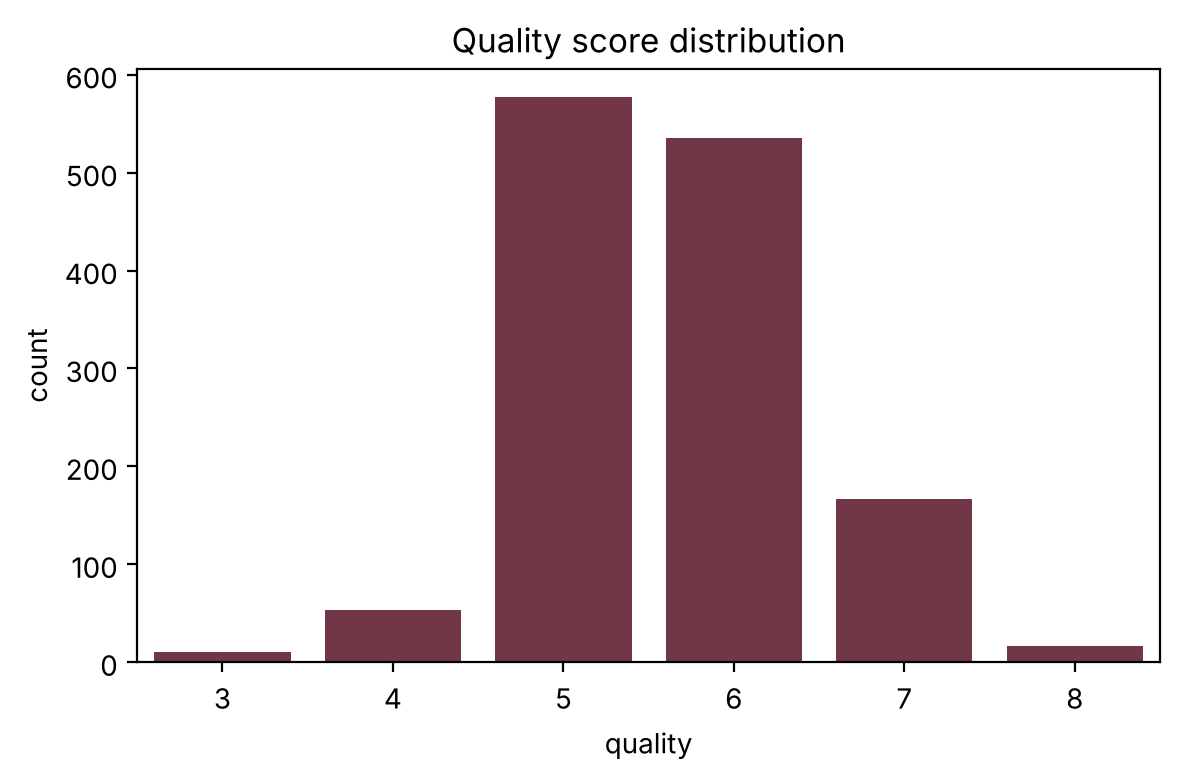

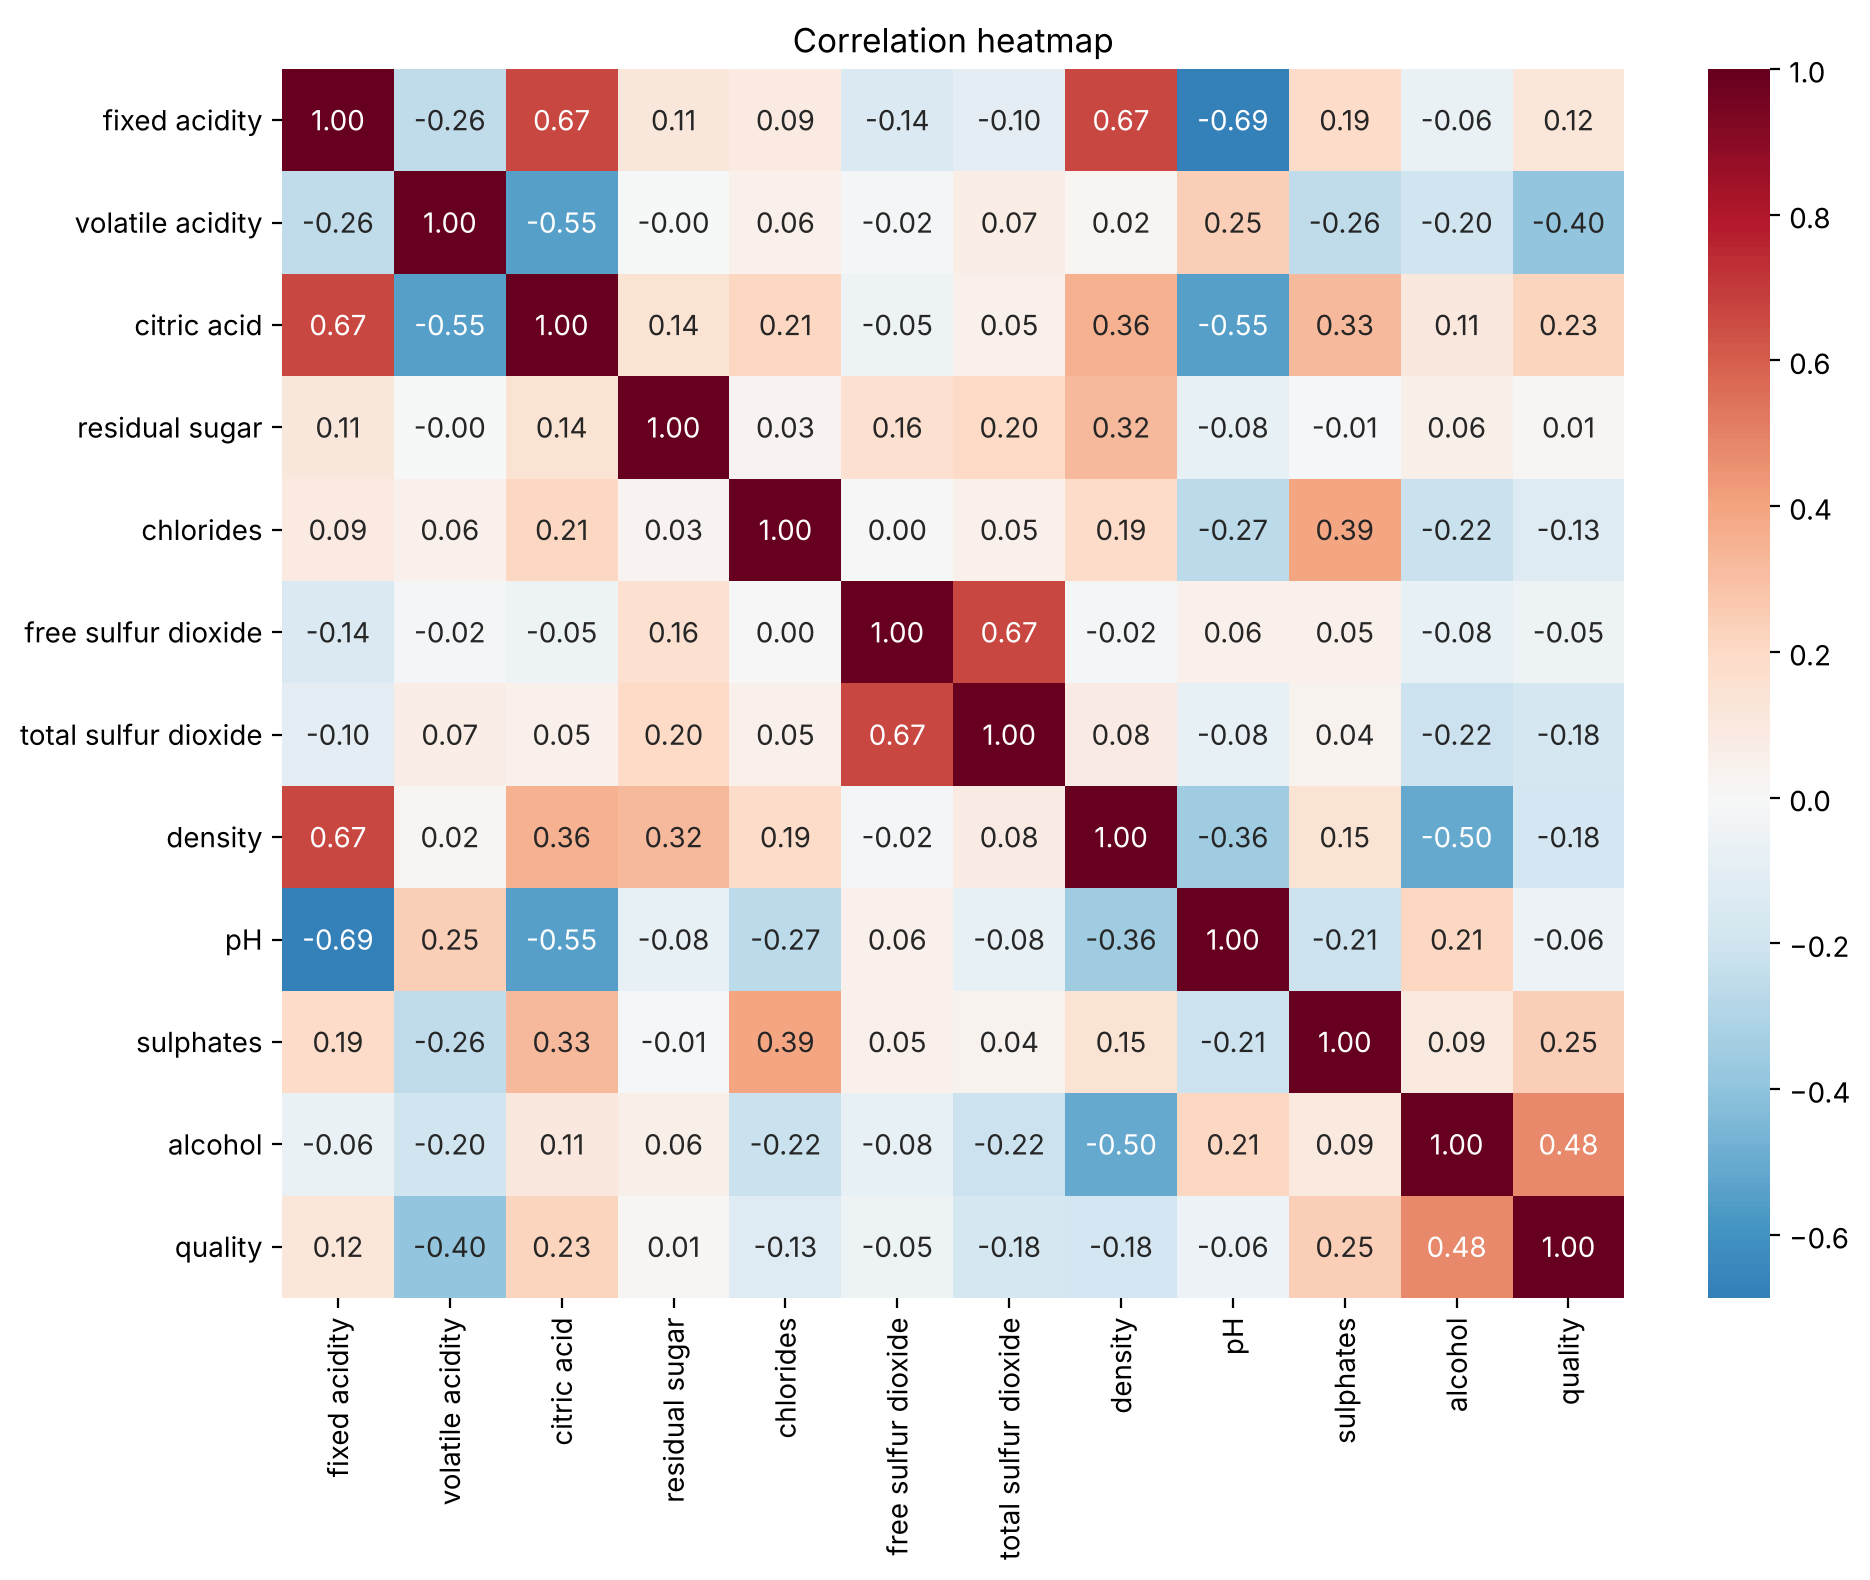

In [2]:
# ---------- EDA ----------
plt.figure(figsize=(6, 4))
sns.countplot(x="quality", data=df, color="#7b2d43")
plt.title("Quality score distribution"); plt.tight_layout()
plt.savefig("images/quality_distribution.png", dpi=150); plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation heatmap"); plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=150); plt.show()

## Target

In [3]:
# ---------- Target ----------
df["good"] = (df["quality"] >= 7).astype(int)
print("\nClass balance:\n", df["good"].value_counts(normalize=True).round(3))
X, y = df.drop(columns=["quality", "good"]), df["good"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
cv = StratifiedKFold(5, shuffle=True, random_state=RS)

def evaluate(name, model):
    p = model.predict(X_te); pr = model.predict_proba(X_te)[:, 1]
    r = dict(Model=name, Accuracy=accuracy_score(y_te, p), Precision=precision_score(y_te, p),
             Recall=recall_score(y_te, p), F1=f1_score(y_te, p), ROC_AUC=roc_auc_score(y_te, pr))
    print(f"\n=== {name} ===\n", classification_report(y_te, p, target_names=["Not good", "Good"]))
    return r, p, pr

results, preds = [], {}


Class balance:
 good
0    0.865
1    0.135
Name: proportion, dtype: float64


## Decision Tree

In [4]:
# ---------- Decision Tree ----------
dt_base = DecisionTreeClassifier(class_weight="balanced", random_state=RS).fit(X_tr, y_tr)
r, p, pr = evaluate("Decision Tree (baseline)", dt_base); results.append(r)

dt_grid = GridSearchCV(DecisionTreeClassifier(class_weight="balanced", random_state=RS),
    {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [1, 5, 10, 20], "criterion": ["gini", "entropy"]},
    scoring="f1", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
dt = dt_grid.best_estimator_
print("Best DT params:", dt_grid.best_params_)
r, p, pr = evaluate("Decision Tree (tuned)", dt); results.append(r); preds["Decision Tree"] = (p, pr)


=== Decision Tree (baseline) ===
               precision    recall  f1-score   support

    Not good       0.91      0.91      0.91       235
        Good       0.43      0.43      0.43        37

    accuracy                           0.85       272
   macro avg       0.67      0.67      0.67       272
weighted avg       0.85      0.85      0.85       272



Best DT params: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}

=== Decision Tree (tuned) ===
               precision    recall  f1-score   support

    Not good       0.96      0.74      0.84       235
        Good       0.33      0.81      0.47        37

    accuracy                           0.75       272
   macro avg       0.65      0.78      0.66       272
weighted avg       0.88      0.75      0.79       272



## Random Forest

In [5]:
# ---------- Random Forest ----------
rf_base = RandomForestClassifier(class_weight="balanced", random_state=RS, n_jobs=-1).fit(X_tr, y_tr)
r, p, pr = evaluate("Random Forest (baseline)", rf_base); results.append(r)

rf_grid = GridSearchCV(RandomForestClassifier(class_weight="balanced", random_state=RS, n_jobs=-1),
    {"n_estimators": [200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2, 4],
     "max_features": ["sqrt", "log2"]}, scoring="f1", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
rf = rf_grid.best_estimator_
print("Best RF params:", rf_grid.best_params_)
r, p, pr = evaluate("Random Forest (tuned)", rf); results.append(r); preds["Random Forest"] = (p, pr)

res = pd.DataFrame(results).round(3)
res.to_csv("results.csv", index=False)
print("\n", res.to_string(index=False))
print("\n5-fold CV F1 -> DT: %.3f | RF: %.3f" % (cross_val_score(dt, X, y, cv=cv, scoring="f1").mean(),
                                               cross_val_score(rf, X, y, cv=cv, scoring="f1").mean()))


=== Random Forest (baseline) ===
               precision    recall  f1-score   support

    Not good       0.92      0.92      0.92       235
        Good       0.50      0.49      0.49        37

    accuracy                           0.86       272
   macro avg       0.71      0.70      0.71       272
weighted avg       0.86      0.86      0.86       272



Best RF params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'n_estimators': 200}

=== Random Forest (tuned) ===
               precision    recall  f1-score   support

    Not good       0.94      0.90      0.92       235
        Good       0.50      0.62      0.55        37

    accuracy                           0.86       272
   macro avg       0.72      0.76      0.74       272
weighted avg       0.88      0.86      0.87       272


                    Model  Accuracy  Precision  Recall    F1  ROC_AUC
Decision Tree (baseline)     0.846      0.432   0.432 0.432    0.672
   Decision Tree (tuned)     0.754      0.333   0.811 0.472    0.850
Random Forest (baseline)     0.864      0.500   0.486 0.493    0.876
   Random Forest (tuned)     0.864      0.500   0.622 0.554    0.882



5-fold CV F1 -> DT: 0.444 | RF: 0.563


## Plots

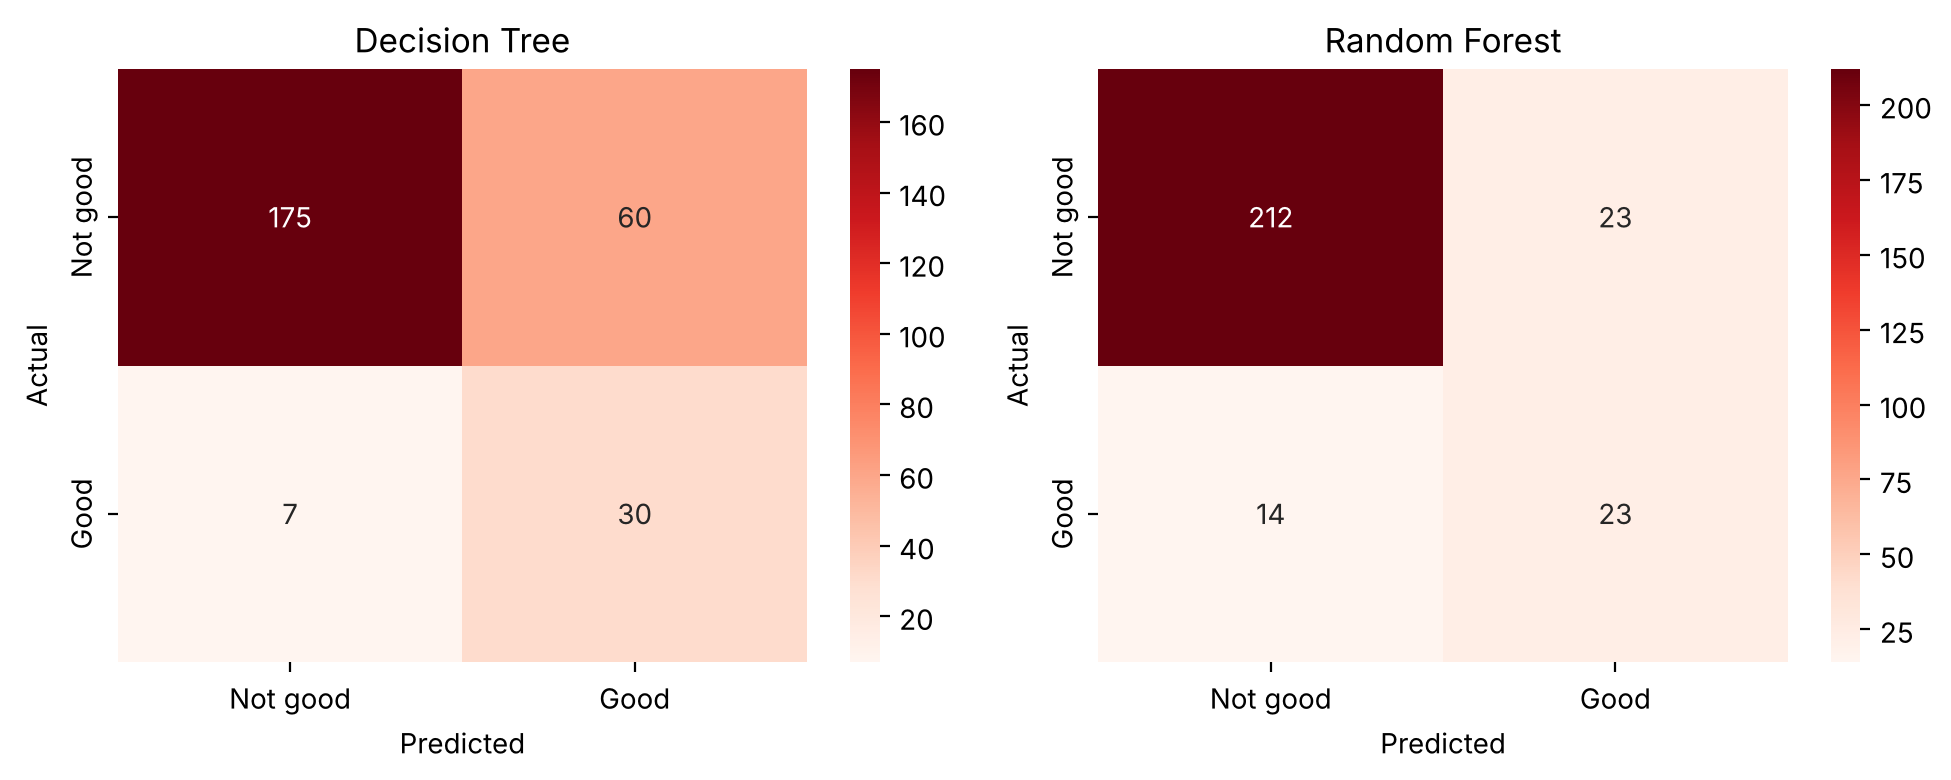

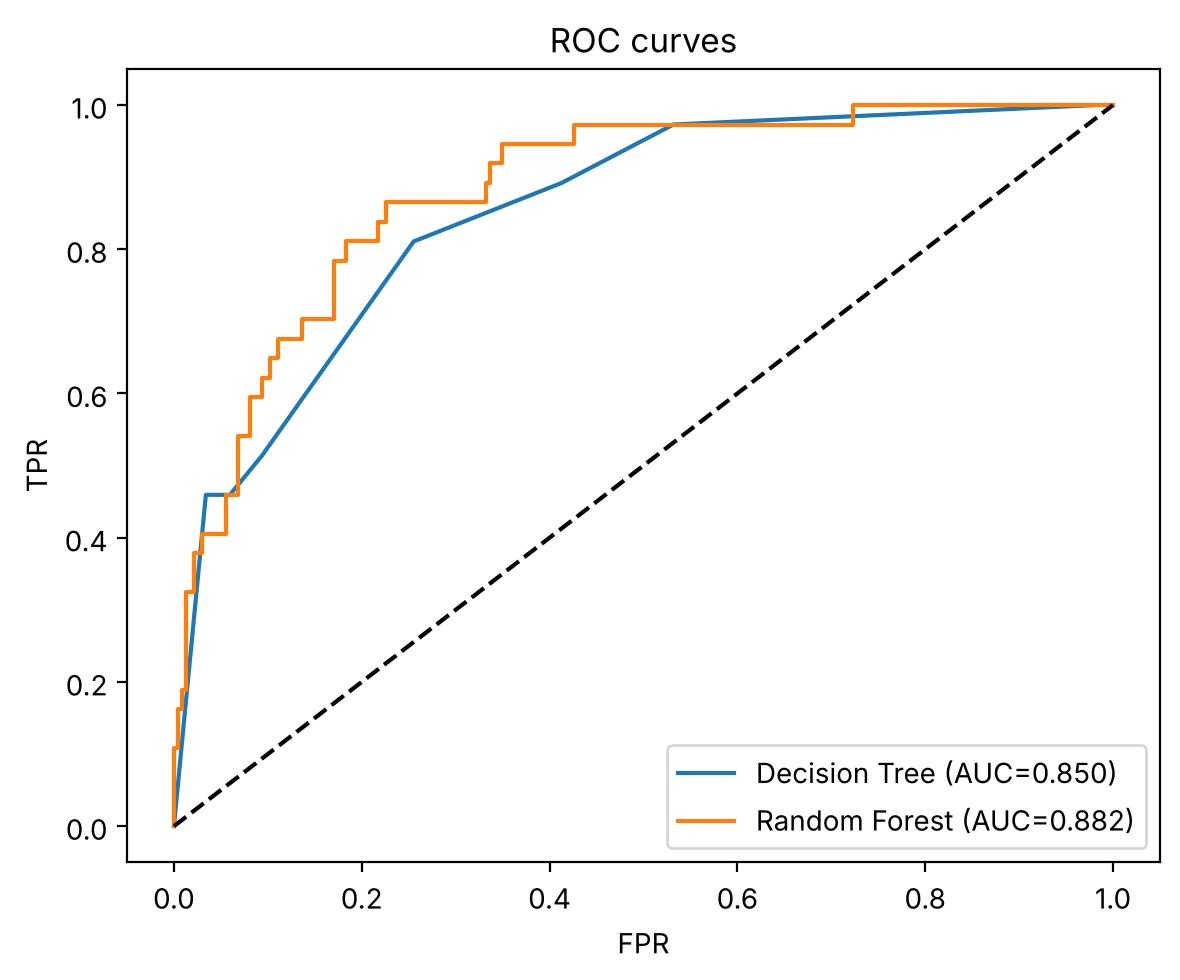

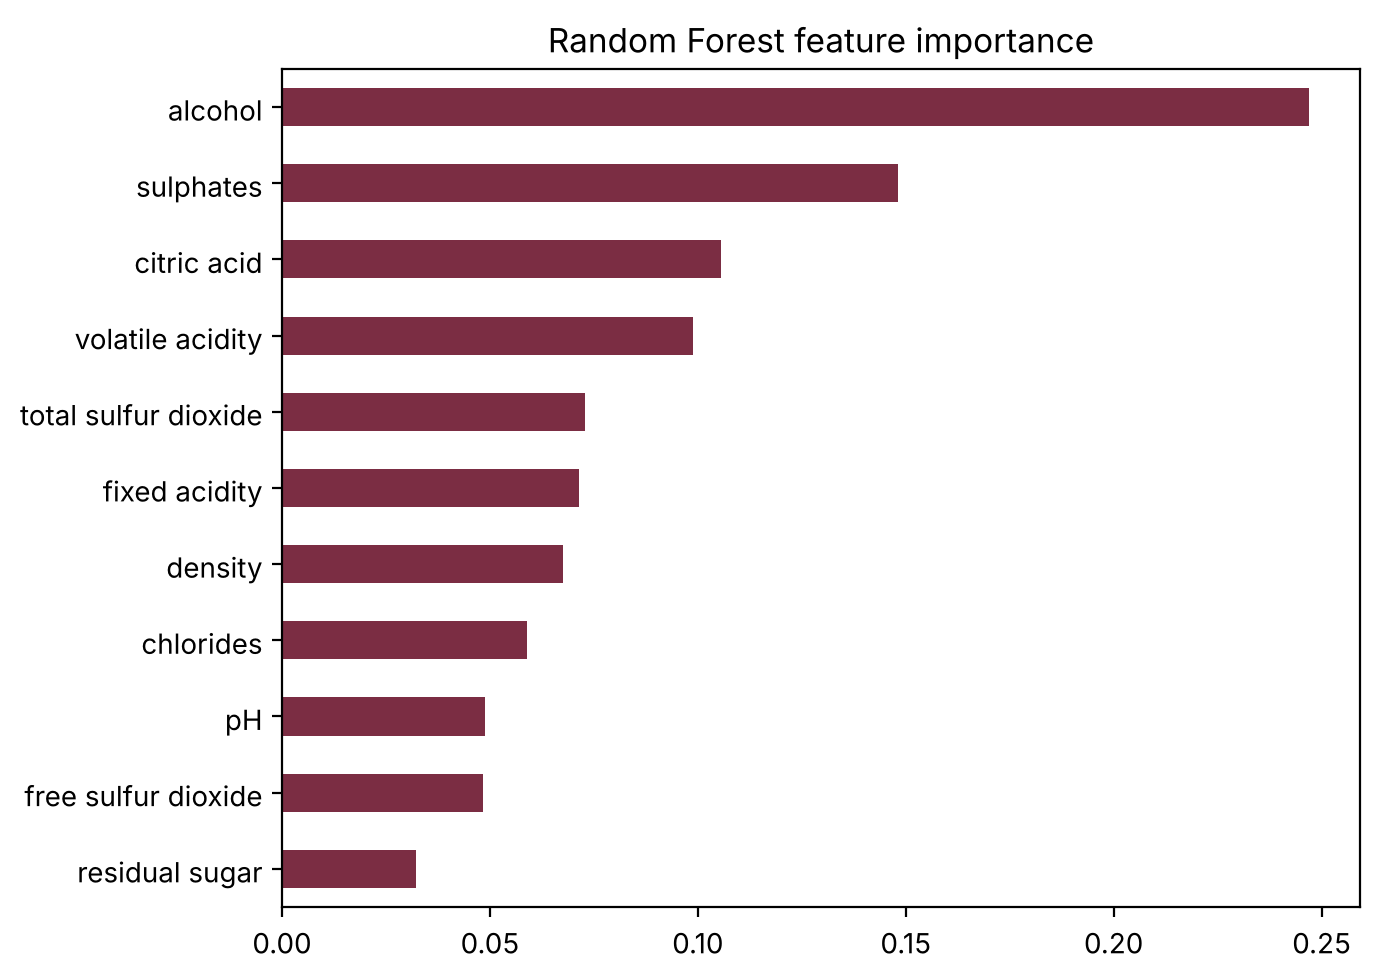


Top features:
 alcohol                 0.247
sulphates               0.148
citric acid             0.106
volatile acidity        0.099
total sulfur dioxide    0.073
dtype: float64


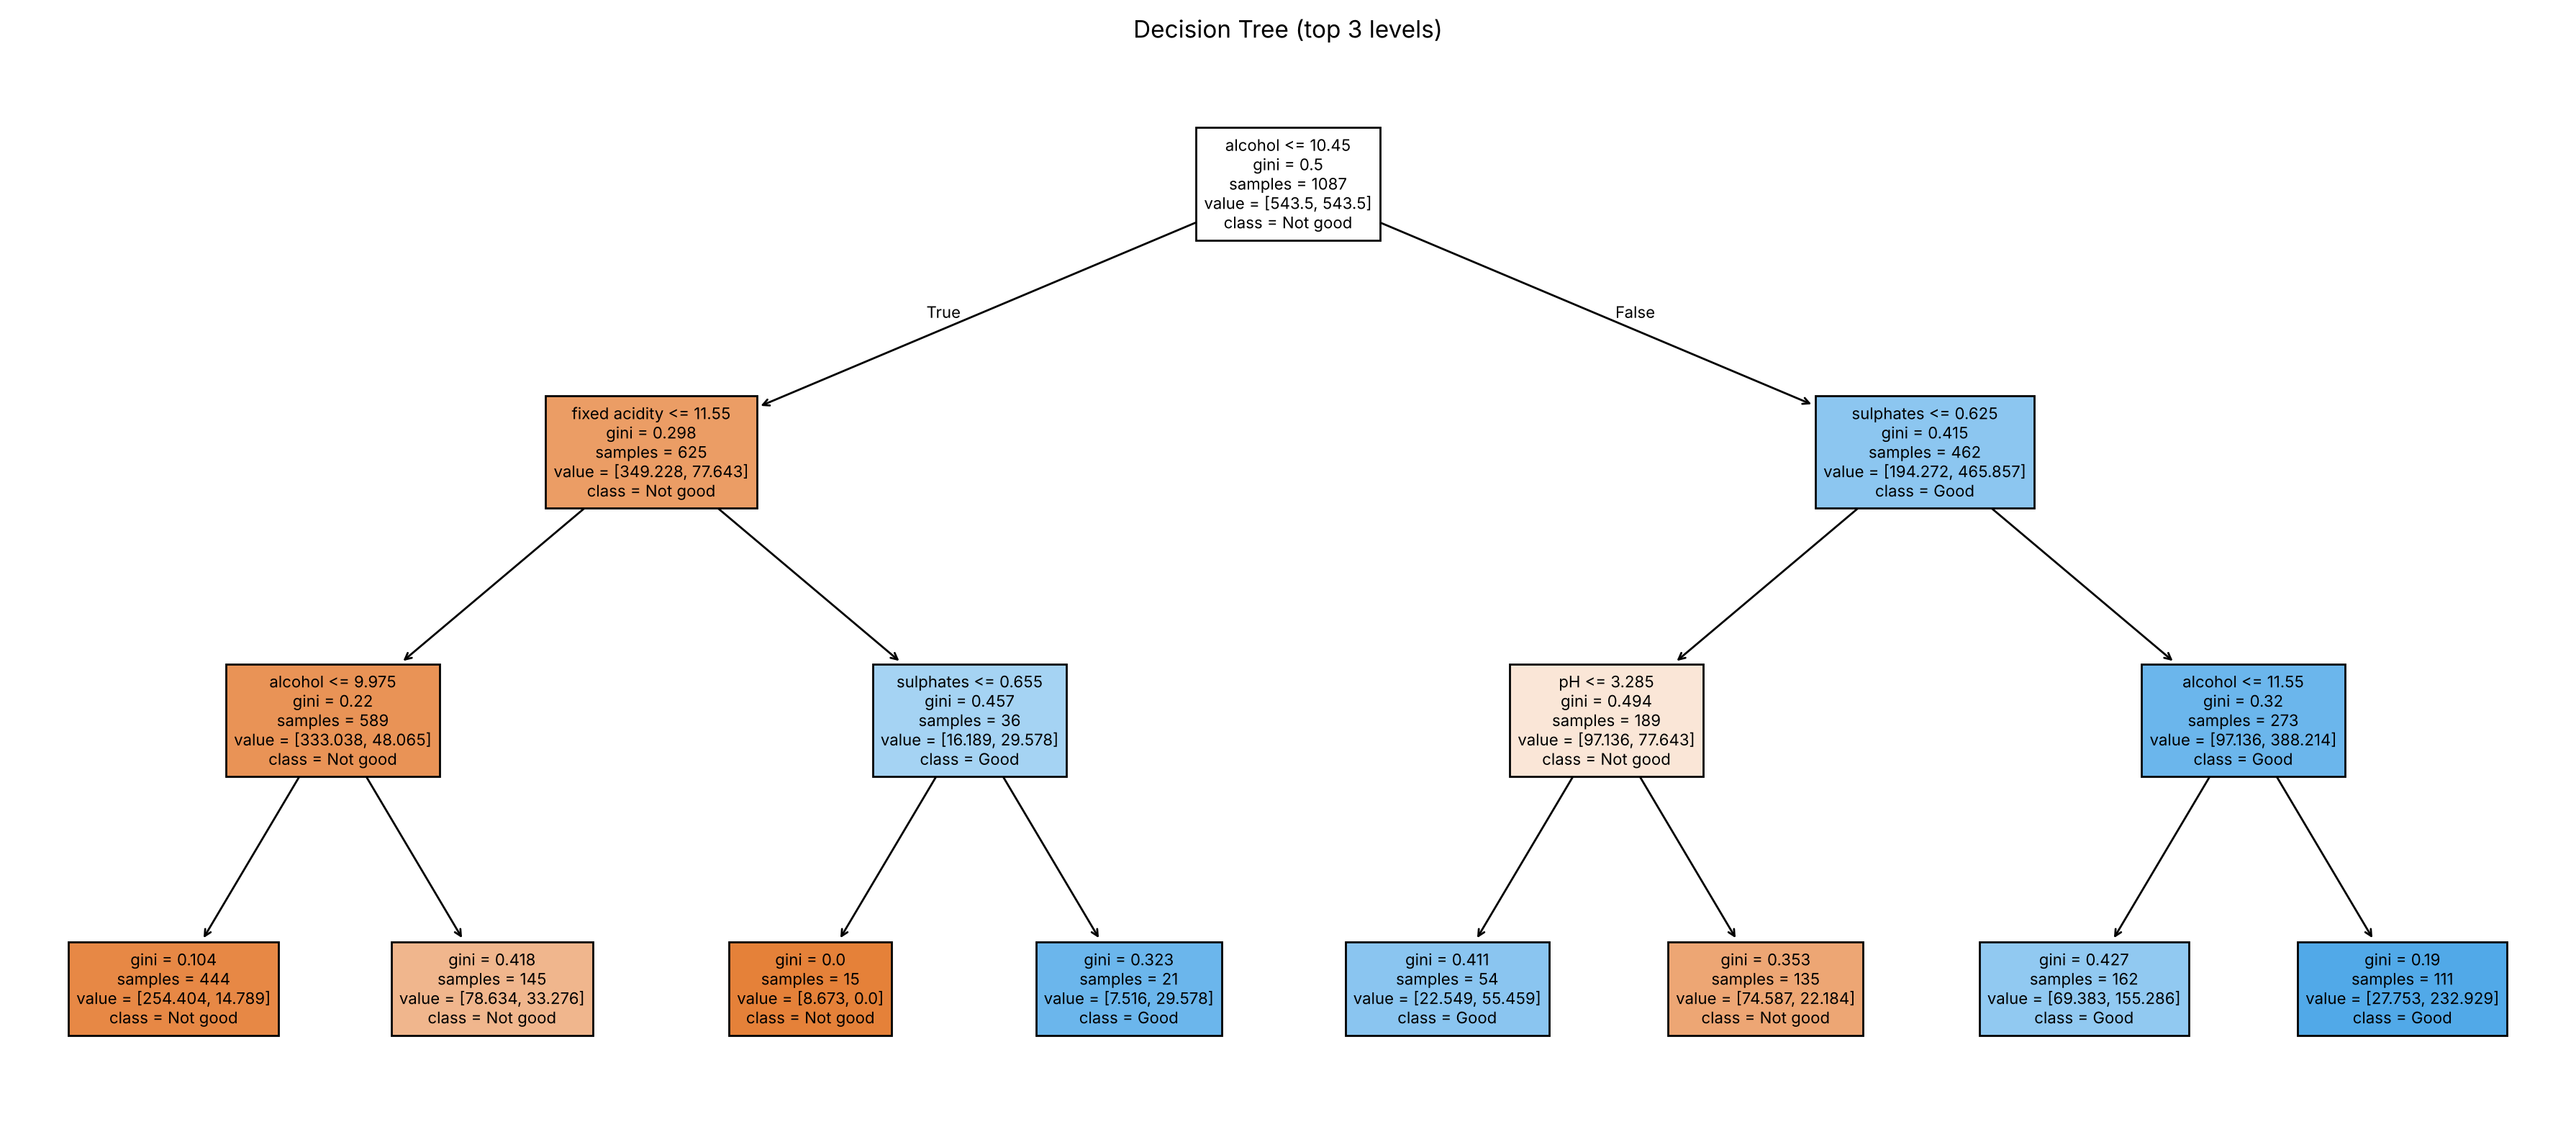

In [6]:
# ---------- Plots ----------
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (n, (p, _)) in zip(ax, preds.items()):
    sns.heatmap(confusion_matrix(y_te, p), annot=True, fmt="d", cmap="Reds", ax=a,
                xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
    a.set_title(n); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.savefig("images/confusion_matrices.png", dpi=150); plt.show()

plt.figure(figsize=(6, 5))
for n, (_, pr) in preds.items():
    fpr, tpr, _ = roc_curve(y_te, pr); plt.plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_te, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC curves"); plt.legend()
plt.tight_layout(); plt.savefig("images/roc_curves.png", dpi=150); plt.show()

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(7, 5)); imp.plot.barh(color="#7b2d43"); plt.title("Random Forest feature importance")
plt.tight_layout(); plt.savefig("images/feature_importance.png", dpi=150); plt.show()
print("\nTop features:\n", imp.sort_values(ascending=False).head(5).round(3))

plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=X.columns, class_names=["Not good", "Good"], filled=True, max_depth=3, fontsize=8)
plt.title("Decision Tree (top 3 levels)"); plt.tight_layout()
plt.savefig("images/decision_tree.png", dpi=130); plt.show()

## Save numbers used in the report

In [7]:
# ---------- Save numbers used in the report ----------
import json
cm = {n: confusion_matrix(y_te, p).tolist() for n, (p, _) in preds.items()}
json.dump({"n_train": len(X_tr), "n_test": len(X_te), "n_after_dedup": len(df),
           "pos_rate": float(y.mean()), "confusion": cm,
           "dt_params": dt_grid.best_params_, "rf_params": rf_grid.best_params_,
           "cv_dt": float(cross_val_score(dt, X, y, cv=cv, scoring="f1").mean()),
           "cv_rf": float(cross_val_score(rf, X, y, cv=cv, scoring="f1").mean()),
           "importance": imp.sort_values(ascending=False).round(4).to_dict(),
           "quality_counts": df["quality"].value_counts().sort_index().to_dict()},
          open("metrics.json", "w"), indent=2)
df.drop(columns=["good"]).describe().T[["mean","std","min","max"]].round(3).to_csv("feature_summary.csv")